# AI-Powered Customer Retention Analytics
### End-to-end customer churn prediction, explainability, risk segmentation and retention planning

This notebook builds a reproducible machine-learning workflow for customer churn analysis. It covers data validation, cleaning, EDA, feature engineering, leakage-safe preprocessing, model comparison, threshold selection, final evaluation, explainability, customer risk segmentation, retention actions and exportable business outputs.

**Default dataset:** IBM Telco Customer Churn sample (7,043 customer records). You can upload your own CSV, provided it contains a binary churn target such as `Churn` with values `Yes/No` or `1/0`.

> **Important:** This is an educational portfolio project. The IBM dataset is a cross-sectional sample, not a longitudinal production dataset. Model scores do not establish that a retention offer will prevent churn. Use the output to prioritize human review, not to make automatic customer decisions.

## 1. Environment setup

Run this cell in Google Colab. The core workflow uses pandas, NumPy, scikit-learn, matplotlib and seaborn. XGBoost and SHAP are optional and are not required for the notebook to run.

In [1]:
!pip -q install -U pandas numpy scikit-learn matplotlib seaborn joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [2]:
import os
import re
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = Path("/content/customer_retention_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Environment ready")
print("Output directory:", OUTPUT_DIR)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Environment ready
Output directory: /content/customer_retention_outputs


## 2. Load the dataset

The notebook first tries the public IBM sample CSV. If the download is unavailable, it opens a Colab upload prompt. For a different churn dataset, upload your CSV and set the target column in the next configuration cell.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
DATA_PATH = Path("/content/Telco-Customer-Churn.csv")

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded IBM Telco sample dataset from public source.")
except Exception as exc:
    print("Automatic download failed:", repr(exc))
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError("No CSV uploaded.")
        uploaded_name = next(iter(uploaded))
        DATA_PATH = Path("/content") / uploaded_name
        df = pd.read_csv(DATA_PATH)
    except ImportError:
        raise RuntimeError("Download failed. Upload a CSV when running in Google Colab.")

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())

Loaded IBM Telco sample dataset from public source.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# -------------------- Dataset configuration --------------------
TARGET_COL = "Churn"          # Change this for your dataset, e.g. "Exited"
ID_COL_CANDIDATES = ["customerID", "CustomerID", "customer_id", "id", "ID"]

if TARGET_COL not in df.columns:
    candidates = [c for c in df.columns if c.lower() in {"churn", "exited", "attrition", "target", "label"}]
    raise ValueError(f"Target '{TARGET_COL}' not found. Available target-like columns: {candidates}. Set TARGET_COL correctly.")

print("Target distribution (raw):")
display(df[TARGET_COL].value_counts(dropna=False).to_frame("count"))
print("Target percentages:")
display((df[TARGET_COL].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

Target distribution (raw):


,count
Churn,
No,5174
Yes,1869


Target percentages:


,percent
Churn,
No,73.46
Yes,26.54


## 3. Data quality checks and cleaning

For the IBM Telco data, `TotalCharges` is stored as text and has blank values for a small number of new customers. We convert it to numeric and let the modeling pipeline impute missing values. Duplicate records are reviewed and removed. The customer identifier is retained for reporting but excluded from model features.

In [5]:
df = df.copy()
df.columns = [str(c).strip() for c in df.columns]

# Normalize common whitespace-only strings to missing.
df = df.replace(r"^\s*$", np.nan, regex=True)

if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Drop exact duplicate rows.
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Normalize target labels to 0/1.
def normalize_target(series):
    if pd.api.types.is_numeric_dtype(series):
        values = set(series.dropna().unique())
        if values.issubset({0, 1}):
            return series.astype("Int64").astype(float)
    mapping = {
        "yes": 1, "y": 1, "true": 1, "1": 1, "churn": 1, "exited": 1,
        "no": 0, "n": 0, "false": 0, "0": 0, "retained": 0, "stay": 0
    }
    normalized = series.astype(str).str.strip().str.lower().map(mapping)
    if normalized.isna().any():
        unknown = sorted(series[normalized.isna()].dropna().astype(str).unique().tolist())
        raise ValueError(f"Unrecognized target labels: {unknown}. Update normalize_target() for your target values.")
    return normalized.astype(int)

df[TARGET_COL] = normalize_target(df[TARGET_COL])
df = df.dropna(subset=[TARGET_COL]).copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)

id_col = next((c for c in ID_COL_CANDIDATES if c in df.columns), None)
print("Duplicate rows removed:", duplicate_rows)
print("Customer ID column:", id_col)
print("Cleaned shape:", df.shape)
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

Duplicate rows removed: 0
Customer ID column: customerID
Cleaned shape: (7043, 21)


,missing_count
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


## 4. Exploratory data analysis (EDA)

Start with churn prevalence, numeric distributions and churn rates across categorical segments. These charts are descriptive; differences between groups are associations, not causal effects.

Overall churn rate: 26.54%
Customers: 7,043


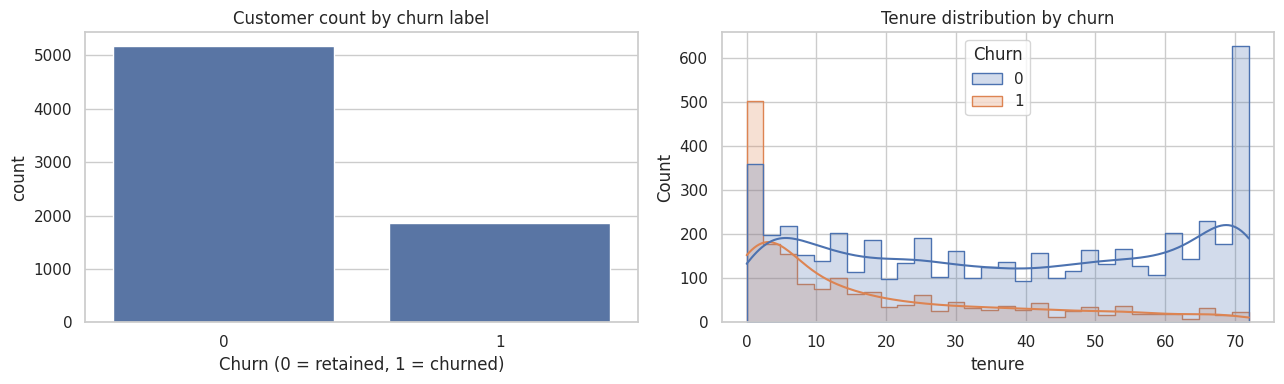

In [6]:
churn_rate = df[TARGET_COL].mean()
print(f"Overall churn rate: {churn_rate:.2%}")
print(f"Customers: {len(df):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x=TARGET_COL, ax=axes[0])
axes[0].set_title("Customer count by churn label")
axes[0].set_xlabel("Churn (0 = retained, 1 = churned)")
sns.histplot(data=df, x="tenure", hue=TARGET_COL, bins=30, kde=True, ax=axes[1], element="step")
axes[1].set_title("Tenure distribution by churn")
plt.tight_layout()
plt.show()

Churn,Retained mean,Churned mean
SeniorCitizen,0.13,0.25
tenure,37.57,17.98
MonthlyCharges,61.27,74.44
TotalCharges,2555.34,1531.80


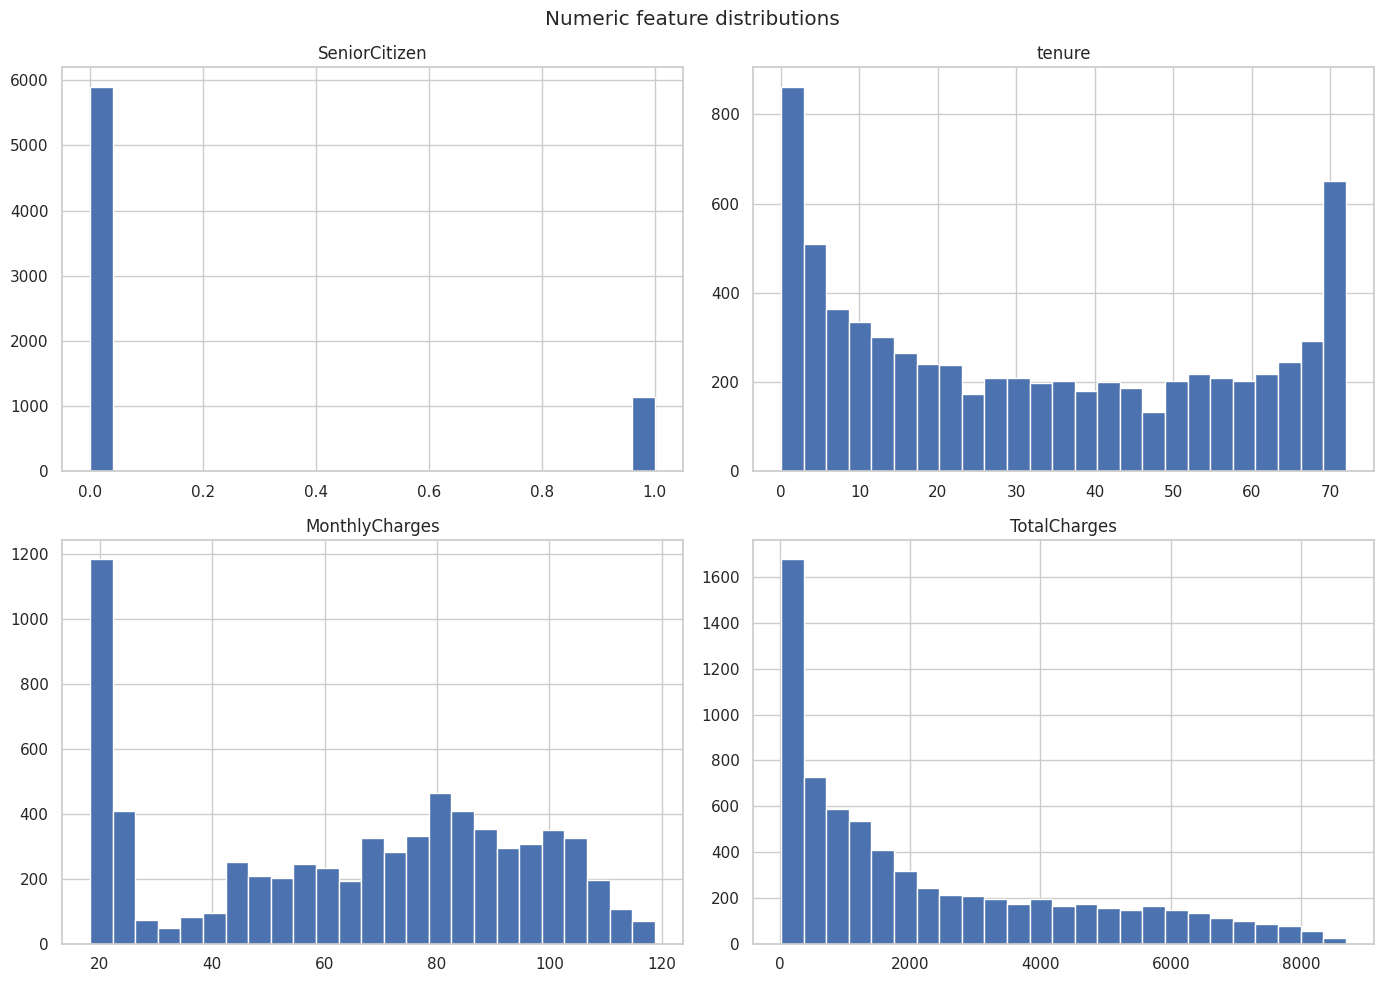

In [7]:
numeric_cols_raw = df.select_dtypes(include=np.number).columns.drop(TARGET_COL, errors="ignore").tolist()
if numeric_cols_raw:
    display(df.groupby(TARGET_COL)[numeric_cols_raw].mean().T.rename(columns={0:"Retained mean", 1:"Churned mean"}).round(2))
    df[numeric_cols_raw].hist(figsize=(14, 10), bins=25)
    plt.suptitle("Numeric feature distributions")
    plt.tight_layout()
    plt.show()

Churn rate by gender


,churn_rate,count
gender,,
Female,26.9%,3488
Male,26.2%,3555


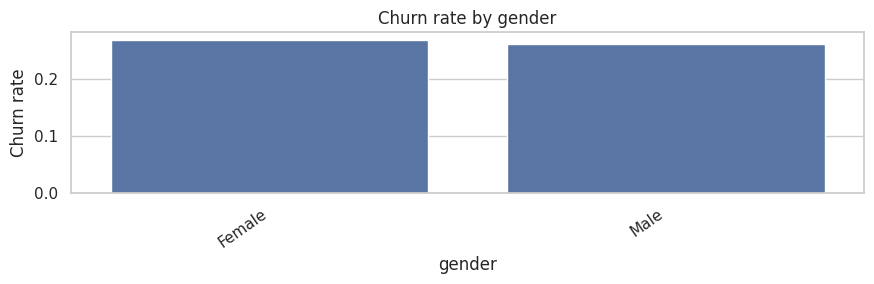

Churn rate by Partner


,churn_rate,count
Partner,,
No,33.0%,3641
Yes,19.7%,3402


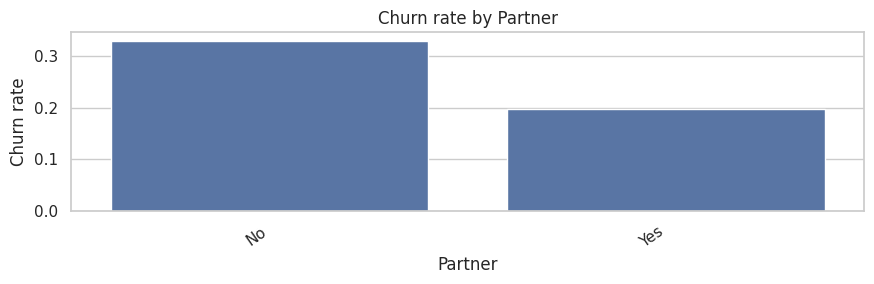

Churn rate by Dependents


,churn_rate,count
Dependents,,
No,31.3%,4933
Yes,15.5%,2110


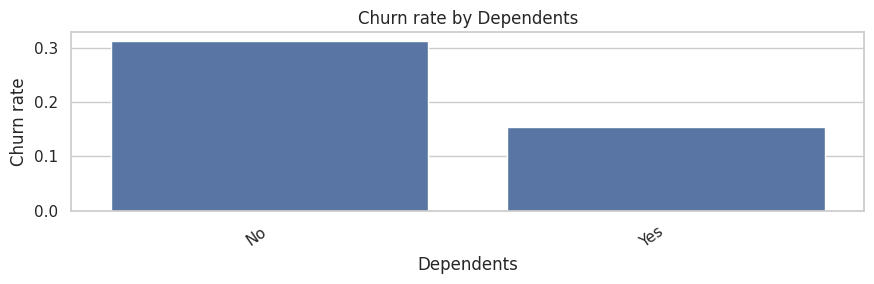

Churn rate by PhoneService


,churn_rate,count
PhoneService,,
Yes,26.7%,6361
No,24.9%,682


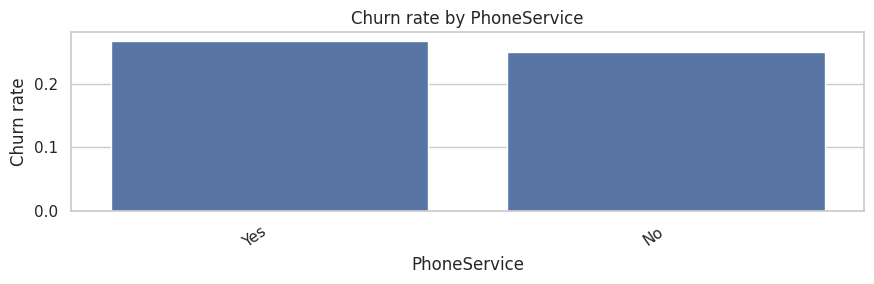

Churn rate by MultipleLines


,churn_rate,count
MultipleLines,,
Yes,28.6%,2971
No,25.0%,3390
No phone service,24.9%,682


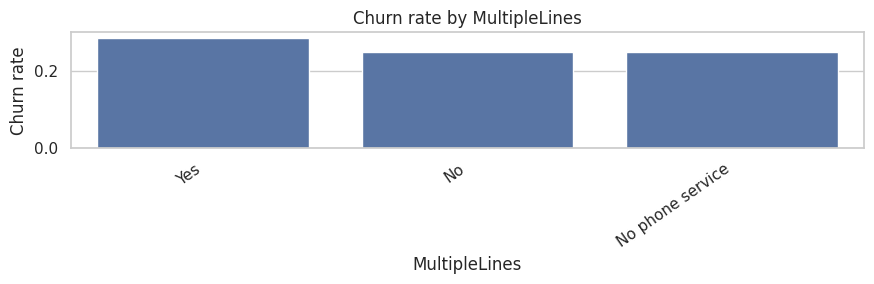

Churn rate by InternetService


,churn_rate,count
InternetService,,
Fiber optic,41.9%,3096
DSL,19.0%,2421
No,7.4%,1526


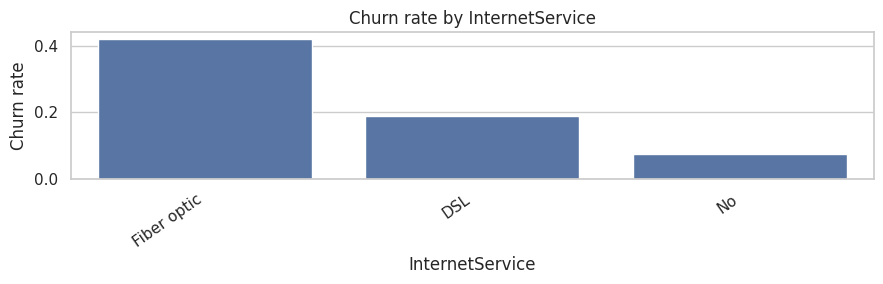

Churn rate by OnlineSecurity


,churn_rate,count
OnlineSecurity,,
No,41.8%,3498
Yes,14.6%,2019
No internet service,7.4%,1526


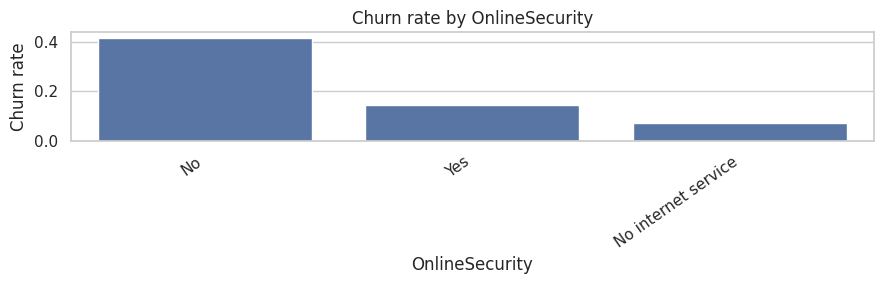

Churn rate by OnlineBackup


,churn_rate,count
OnlineBackup,,
No,39.9%,3088
Yes,21.5%,2429
No internet service,7.4%,1526


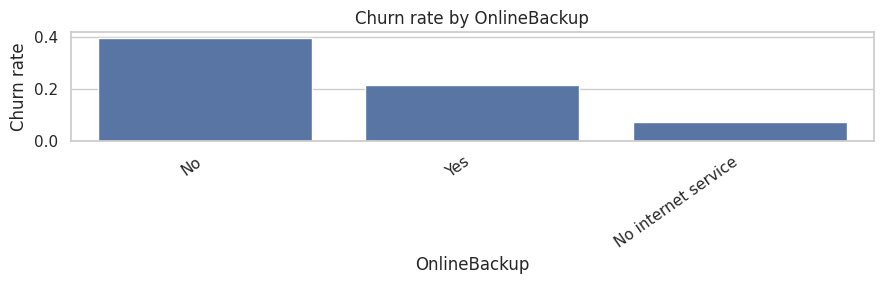

Churn rate by DeviceProtection


,churn_rate,count
DeviceProtection,,
No,39.1%,3095
Yes,22.5%,2422
No internet service,7.4%,1526


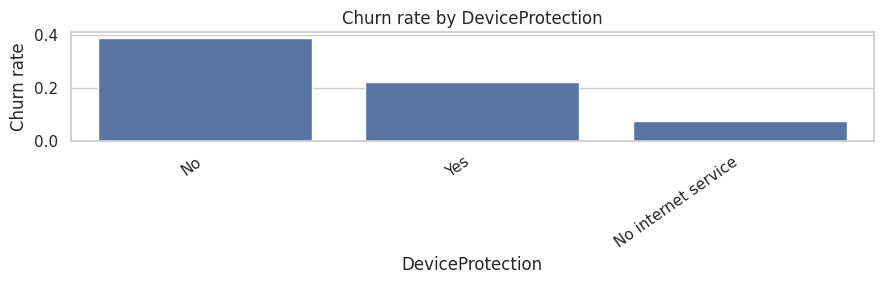

In [8]:
categorical_cols_raw = [c for c in df.select_dtypes(include=["object", "category", "bool"]).columns if c != TARGET_COL]
for col in categorical_cols_raw[:10]:
    rate = df.groupby(col, dropna=False)[TARGET_COL].agg(["mean", "count"]).sort_values("mean", ascending=False)
    if rate.shape[0] <= 15:
        print(f"Churn rate by {col}")
        display(rate.rename(columns={"mean":"churn_rate"}).style.format({"churn_rate":"{:.1%}"}))
        plt.figure(figsize=(9, 3))
        sns.barplot(x=rate.index.astype(str), y=rate["mean"])
        plt.title(f"Churn rate by {col}")
        plt.ylabel("Churn rate")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

## 5. Feature engineering

Create a few interpretable fields when the source columns exist. Do not create features using the target. The customer ID is excluded from training to avoid learning arbitrary identifiers.

In [9]:
def add_business_features(data):
    out = data.copy()
    if "tenure" in out.columns:
        out["tenure_band"] = pd.cut(
            pd.to_numeric(out["tenure"], errors="coerce"),
            bins=[-1, 6, 12, 24, 48, 72, np.inf],
            labels=["0-6m", "7-12m", "13-24m", "25-48m", "49-72m", "72m+"]
        ).astype("object")
    service_cols = [
        c for c in ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
        if c in out.columns
    ]
    if service_cols:
        def yes_count(row):
            return sum(str(v).strip().lower() == "yes" for v in row)
        out["service_count"] = out[service_cols].apply(yes_count, axis=1)
    if {"MonthlyCharges", "TotalCharges"}.issubset(out.columns):
        monthly = pd.to_numeric(out["MonthlyCharges"], errors="coerce")
        total = pd.to_numeric(out["TotalCharges"], errors="coerce")
        out["total_to_monthly_ratio"] = total / monthly.replace(0, np.nan)
    return out

model_df = add_business_features(df)
excluded_cols = [TARGET_COL]
if id_col:
    excluded_cols.append(id_col)

X = model_df.drop(columns=excluded_cols, errors="ignore")
y = model_df[TARGET_COL].astype(int)

# Drop columns that contain only one non-null value.
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constant_cols)

print("Feature matrix:", X.shape)
print("Dropped constant columns:", constant_cols)
print("Churn prevalence:", round(y.mean(), 4))

Feature matrix: (7043, 22)
Dropped constant columns: []
Churn prevalence: 0.2654


## 6. Train / validation / test split

Use a stratified three-way split. The test set is held back until the final evaluation. Preprocessing is fitted inside scikit-learn pipelines using training data only, preventing information leakage.

In [10]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Train:", X_train.shape, "Validation:", X_valid.shape, "Test:", X_test.shape)
print("Numeric features:", len(numeric_features), "Categorical features:", len(categorical_features))

Train: (4507, 22) Validation: (1127, 22) Test: (1409, 22)
Numeric features: 6 Categorical features: 16


## 7. Model training and comparison

Compare an interpretable Logistic Regression baseline with tree-based models. Class weighting is used where supported to help address imbalance. We do not apply SMOTE before splitting; doing so would leak information into validation/test data.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=400, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

fitted_models = {}
comparison = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocess", clone(preprocessor)), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    valid_prob = pipe.predict_proba(X_valid)[:, 1]
    valid_pred = (valid_prob >= 0.50).astype(int)
    comparison.append({
        "model": name,
        "ROC_AUC": roc_auc_score(y_valid, valid_prob),
        "PR_AUC": average_precision_score(y_valid, valid_prob),
        "Recall@0.50": recall_score(y_valid, valid_pred, zero_division=0),
        "Precision@0.50": precision_score(y_valid, valid_pred, zero_division=0),
        "F1@0.50": f1_score(y_valid, valid_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison).sort_values(["PR_AUC", "ROC_AUC"], ascending=False)
display(comparison_df.style.format({c:"{:.3f}" for c in comparison_df.columns if c != "model"}))
best_model_name = comparison_df.iloc[0]["model"]
best_model = fitted_models[best_model_name]
print("Selected model by validation PR-AUC, then ROC-AUC:", best_model_name)

,model,ROC_AUC,PR_AUC,Recall@0.50,Precision@0.50,F1@0.50
0,Logistic Regression,0.851,0.676,0.783,0.526,0.629
1,Random Forest,0.839,0.645,0.629,0.608,0.618
2,Extra Trees,0.834,0.627,0.669,0.578,0.620


Selected model by validation PR-AUC, then ROC-AUC: Logistic Regression


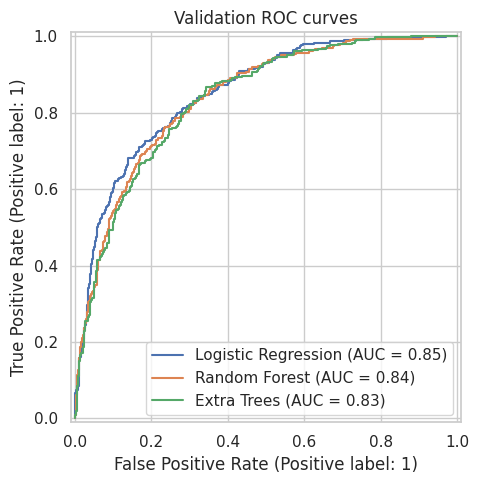

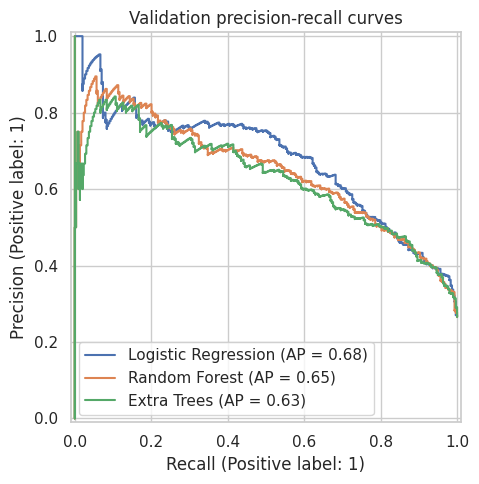

In [12]:
plt.figure(figsize=(8, 5))
for name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_valid, y_valid, name=name, ax=plt.gca())
plt.title("Validation ROC curves")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for name, pipe in fitted_models.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_valid, y_valid, name=name, ax=plt.gca())
plt.title("Validation precision-recall curves")
plt.tight_layout()
plt.show()

## 8. Select a decision threshold using validation data

A default 0.50 cutoff is not always appropriate. For retention use cases, missing a customer who is likely to churn can be costly, but contacting too many customers also has a cost. This section selects a threshold using the validation set and an F2 score (recall-weighted). Adjust the business costs in the economics section before using this operationally.

,threshold,precision,recall,f1,f2
11,0.320,0.432,0.910,0.586,0.745
10,0.300,0.424,0.910,0.579,0.740
5,0.200,0.391,0.950,0.554,0.738
7,0.240,0.403,0.930,0.562,0.737
2,0.140,0.369,0.980,0.537,0.737
9,0.280,0.415,0.913,0.571,0.736
6,0.220,0.395,0.936,0.556,0.735
3,0.160,0.373,0.970,0.539,0.735
12,0.340,0.436,0.886,0.584,0.734
4,0.180,0.381,0.957,0.545,0.734


Chosen threshold (validation F2): 0.32


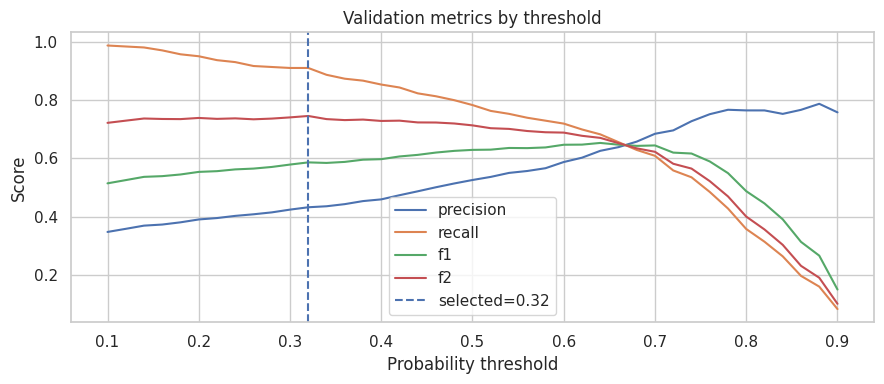

In [13]:
valid_prob = best_model.predict_proba(X_valid)[:, 1]
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.02):
    pred = (valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0),
        "f2": (5 * precision_score(y_valid, pred, zero_division=0) * recall_score(y_valid, pred, zero_division=0)) /
              max(4 * precision_score(y_valid, pred, zero_division=0) + recall_score(y_valid, pred, zero_division=0), 1e-12)
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.sort_values("f2", ascending=False).head(10).style.format({c:"{:.3f}" for c in threshold_df.columns}))
best_threshold = float(threshold_df.loc[threshold_df["f2"].idxmax(), "threshold"])
print(f"Chosen threshold (validation F2): {best_threshold:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
for metric in ["precision", "recall", "f1", "f2"]:
    ax.plot(threshold_df["threshold"], threshold_df[metric], label=metric)
ax.axvline(best_threshold, linestyle="--", label=f"selected={best_threshold:.2f}")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Score")
ax.set_title("Validation metrics by threshold")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Final model evaluation on the untouched test set

The selected model and threshold are evaluated once on the test set. The test results are the best estimate in this notebook of performance on unseen records from the same data-generating process.

,test_value
model,Logistic Regression
threshold,0.32
accuracy,0.668559
precision,0.440461
recall,0.919786
f1,0.595671
roc_auc,0.845808
pr_auc,0.652248


              precision    recall  f1-score   support

    Retained       0.95      0.58      0.72      1035
     Churned       0.44      0.92      0.60       374

    accuracy                           0.67      1409
   macro avg       0.70      0.75      0.66      1409
weighted avg       0.82      0.67      0.69      1409



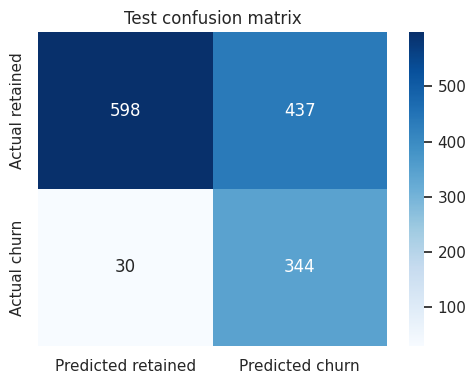

In [14]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

test_metrics = {
    "model": best_model_name,
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "pr_auc": average_precision_score(y_test, test_prob)
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0:"test_value"}))
print(classification_report(y_test, test_pred, target_names=["Retained", "Churned"], zero_division=0))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted retained", "Predicted churn"],
            yticklabels=["Actual retained", "Actual churn"])
plt.title("Test confusion matrix")
plt.tight_layout()
plt.show()

## 10. Explainability and churn drivers

Permutation importance measures how much test-set ROC-AUC changes when a feature is shuffled. It works with the full pipeline and avoids relying on model-specific feature importance scales. Results indicate predictive association, not causation.

,feature,importance_mean,importance_std
14,Contract,0.052233,0.004821
7,InternetService,0.041328,0.008682
21,total_to_monthly_ratio,0.033066,0.002103
17,MonthlyCharges,0.027541,0.005071
19,tenure_band,0.011118,0.002345
4,tenure,0.010274,0.001323
20,service_count,0.005019,0.002024
11,TechSupport,0.004228,0.000869
8,OnlineSecurity,0.004107,0.001238
12,StreamingTV,0.002489,0.002104


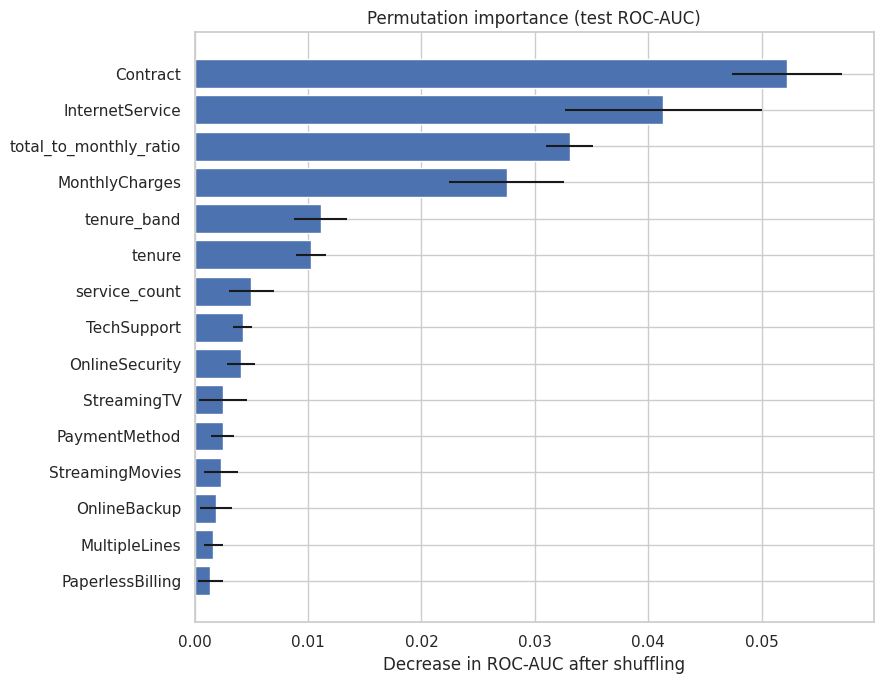

In [15]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc",
    n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(20))
plt.figure(figsize=(9, 7))
top_imp = importance_df.head(15).sort_values("importance_mean")
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.title("Permutation importance (test ROC-AUC)")
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.tight_layout()
plt.show()

### Optional SHAP analysis

SHAP is optional because support varies by estimator and dependency version. The general permutation-importance analysis above remains the notebook's default explainability method.

In [16]:
RUN_SHAP = False  # Change to True to attempt optional SHAP explanations.

if RUN_SHAP:
    try:
        !pip -q install shap
        import shap
        # Explain a small sample of transformed test rows.
        X_sample = X_test.sample(min(150, len(X_test)), random_state=RANDOM_STATE)
        transformed = best_model.named_steps["preprocess"].transform(X_sample)
        feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
        estimator = best_model.named_steps["model"]
        explainer = shap.Explainer(estimator, transformed)
        shap_values = explainer(transformed)
        shap.plots.beeswarm(shap_values, max_display=20)
    except Exception as exc:
        print("SHAP could not be run for this estimator/environment:", repr(exc))
else:
    print("SHAP skipped. Set RUN_SHAP=True to try it.")

SHAP skipped. Set RUN_SHAP=True to try it.


## 11. Score all customers and create churn-risk segments

The model is refit on train + validation data after the threshold has been selected. It then scores the full customer population. Risk bands are based on predicted probability and are configurable; they are not calibrated guarantees.

,risk_segment,customers,average_churn_probability,actual_churn_rate,customer_share
0,Low,3547,14.6%,6.3%,50.4%
1,Medium,1775,54.7%,30.1%,25.2%
2,High,1721,82.3%,64.6%,24.4%


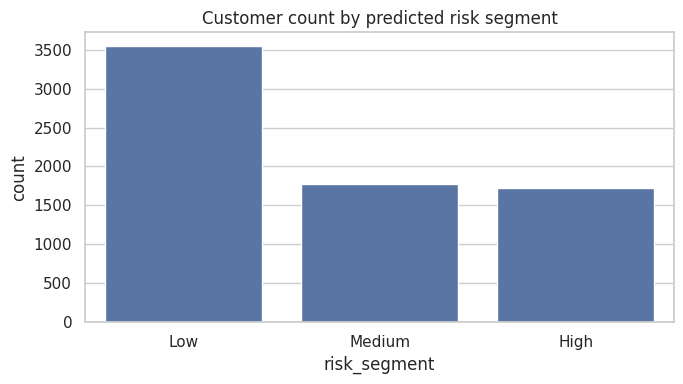

In [17]:
final_model = clone(best_model)
X_development = pd.concat([X_train, X_valid], axis=0)
y_development = pd.concat([y_train, y_valid], axis=0)
final_model.fit(X_development, y_development)

population_prob = final_model.predict_proba(X)[:, 1]
scored = model_df.copy()
scored["churn_probability"] = population_prob
scored["predicted_churn"] = (scored["churn_probability"] >= best_threshold).astype(int)

def risk_band(p):
    if p >= 0.70:
        return "High"
    elif p >= 0.40:
        return "Medium"
    return "Low"

scored["risk_segment"] = scored["churn_probability"].apply(risk_band)
scored["risk_segment"] = pd.Categorical(scored["risk_segment"], categories=["Low", "Medium", "High"], ordered=True)

if id_col is None:
    scored.insert(0, "customer_row_id", np.arange(1, len(scored) + 1))
    report_id_col = "customer_row_id"
else:
    report_id_col = id_col

segment_summary = scored.groupby("risk_segment", observed=False).agg(
    customers=(TARGET_COL, "size"),
    average_churn_probability=("churn_probability", "mean"),
    actual_churn_rate=(TARGET_COL, "mean")
).reset_index()
segment_summary["customer_share"] = segment_summary["customers"] / len(scored)
display(segment_summary.style.format({
    "average_churn_probability":"{:.1%}", "actual_churn_rate":"{:.1%}", "customer_share":"{:.1%}"
}))

plt.figure(figsize=(7, 4))
sns.countplot(data=scored, x="risk_segment", order=["Low", "Medium", "High"])
plt.title("Customer count by predicted risk segment")
plt.tight_layout()
plt.show()

## 12. Business-friendly retention action recommendations

The following are example playbook suggestions, not automated interventions. In a real business, validate eligibility, consent, contact preferences, offer economics and fairness before contacting customers. The recommendations use transparent rules based on common Telco fields when available.

In [18]:
def recommend_action(row):
    risk = str(row.get("risk_segment", ""))
    contract = str(row.get("Contract", "")).lower()
    tenure = row.get("tenure", np.nan)
    tech_support = str(row.get("TechSupport", "")).lower()
    online_security = str(row.get("OnlineSecurity", "")).lower()
    monthly = row.get("MonthlyCharges", np.nan)

    if risk == "Low":
        return "Standard engagement: maintain service quality and monitor at normal cadence."
    actions = []
    if "month-to-month" in contract:
        actions.append("Offer a transparent annual-contract benefit or loyalty plan; explain terms clearly.")
    if pd.notna(tenure) and tenure <= 12:
        actions.append("Prioritize onboarding check-in and first-year service experience.")
    if tech_support == "no" or online_security == "no":
        actions.append("Review suitability of technical support/security add-ons; avoid irrelevant upselling.")
    if pd.notna(monthly) and monthly >= scored["MonthlyCharges"].median() if "MonthlyCharges" in scored.columns else False:
        actions.append("Review bill clarity and plan fit; offer a lower-cost plan if appropriate.")
    if not actions:
        actions.append("Conduct a service satisfaction check and investigate recent support or billing issues.")
    return " ".join(actions)

scored["retention_action"] = scored.apply(recommend_action, axis=1)
priority_cols = [report_id_col, "churn_probability", "risk_segment", "predicted_churn", "retention_action"]
for c in ["tenure", "Contract", "MonthlyCharges", "TotalCharges", "InternetService", "TechSupport"]:
    if c in scored.columns and c not in priority_cols:
        priority_cols.append(c)

priority_customers = scored.sort_values("churn_probability", ascending=False)[priority_cols]
display(priority_customers.head(20))
display(scored.groupby(["risk_segment", "retention_action"], observed=False).size().reset_index(name="customers").head(20))

,customerID,churn_probability,risk_segment,predicted_churn,retention_action,tenure,Contract,MonthlyCharges,TotalCharges,InternetService,TechSupport
3380,5178-LMXOP,0.963335,High,1,Offer a transparent annual-contract benefit or...,1,Month-to-month,95.10,95.10,Fiber optic,No
1976,9497-QCMMS,0.963178,High,1,Offer a transparent annual-contract benefit or...,1,Month-to-month,93.55,93.55,Fiber optic,No
4800,9300-AGZNL,0.962800,High,1,Offer a transparent annual-contract benefit or...,1,Month-to-month,94.00,94.00,Fiber optic,No
5989,5567-WSELE,0.962086,High,1,Offer a transparent annual-contract benefit or...,3,Month-to-month,94.60,279.55,Fiber optic,No
3749,4424-TKOPW,0.962019,High,1,Offer a transparent annual-contract benefit or...,2,Month-to-month,93.85,196.75,Fiber optic,No
6368,2720-WGKHP,0.961981,High,1,Offer a transparent annual-contract benefit or...,2,Month-to-month,94.00,181.70,Fiber optic,No
2208,7216-EWTRS,0.961774,High,1,Offer a transparent annual-contract benefit or...,1,Month-to-month,100.80,100.80,Fiber optic,No
1410,7024-OHCCK,0.960989,High,1,Offer a transparent annual-contract benefit or...,2,Month-to-month,93.85,170.85,Fiber optic,No
3159,5150-ITWWB,0.959999,High,1,Offer a transparent annual-contract benefit or...,3,Month-to-month,94.85,335.75,Fiber optic,No
997,1374-DMZUI,0.958349,High,1,Offer a transparent annual-contract benefit or...,4,Month-to-month,94.30,424.45,Fiber optic,No


,risk_segment,retention_action,customers
0,Low,Offer a transparent annual-contract benefit or...,0
1,Low,Offer a transparent annual-contract benefit or...,0
2,Low,Offer a transparent annual-contract benefit or...,0
3,Low,Offer a transparent annual-contract benefit or...,0
4,Low,Offer a transparent annual-contract benefit or...,0
5,Low,Offer a transparent annual-contract benefit or...,0
6,Low,Offer a transparent annual-contract benefit or...,0
7,Low,Offer a transparent annual-contract benefit or...,0
8,Low,Prioritize onboarding check-in and first-year ...,0
9,Low,Prioritize onboarding check-in and first-year ...,0


## 13. Retention economics scenario

Estimate a potential retention campaign's economics using explicit assumptions. This is a scenario calculator, not a causal impact estimate. Replace the assumptions with validated business values before presenting the results.

In [19]:
# -------------------- Editable business assumptions --------------------
AVERAGE_MONTHLY_REVENUE = float(pd.to_numeric(scored["MonthlyCharges"], errors="coerce").median()) if "MonthlyCharges" in scored.columns else 50.0
GROSS_MARGIN = 0.60
EXPECTED_RETAINED_MONTHS = 6
OFFER_COST_PER_CONTACT = 15.0
CONTACT_COST_PER_CUSTOMER = 2.0
ASSUMED_SAVE_RATE = 0.15  # hypothetical campaign save rate among contacted high-risk customers

high_risk = scored[scored["risk_segment"] == "High"]
eligible_customers = len(high_risk)
expected_saved = eligible_customers * ASSUMED_SAVE_RATE
value_per_saved_customer = AVERAGE_MONTHLY_REVENUE * GROSS_MARGIN * EXPECTED_RETAINED_MONTHS
campaign_cost = eligible_customers * (OFFER_COST_PER_CONTACT + CONTACT_COST_PER_CUSTOMER)
expected_retained_value = expected_saved * value_per_saved_customer
net_scenario_value = expected_retained_value - campaign_cost

economics = pd.DataFrame([{
    "high_risk_customers": eligible_customers,
    "assumed_save_rate": ASSUMED_SAVE_RATE,
    "expected_saved_customers": expected_saved,
    "estimated_value_per_saved_customer": value_per_saved_customer,
    "estimated_campaign_cost": campaign_cost,
    "scenario_retained_value": expected_retained_value,
    "scenario_net_value": net_scenario_value
}])
display(economics.style.format({
    "assumed_save_rate":"{:.1%}",
    "estimated_value_per_saved_customer":"${:,.2f}",
    "estimated_campaign_cost":"${:,.2f}",
    "scenario_retained_value":"${:,.2f}",
    "scenario_net_value":"${:,.2f}"
}))
print("Replace the hypothetical save rate and cost assumptions with measured campaign results.")

,high_risk_customers,assumed_save_rate,expected_saved_customers,estimated_value_per_saved_customer,estimated_campaign_cost,scenario_retained_value,scenario_net_value
0,1721,15.0%,258.150000,$253.26,"$29,257.00","$65,379.07","$36,122.07"


Replace the hypothetical save rate and cost assumptions with measured campaign results.


## 14. Segment analysis for business stakeholders

Review churn prevalence and revenue exposure across risk bands and important business dimensions. These summaries help translate the model into operational questions.

In [20]:
if "MonthlyCharges" in scored.columns:
    segment_value = scored.groupby("risk_segment", observed=False).agg(
        customers=("churn_probability", "size"),
        avg_probability=("churn_probability", "mean"),
        monthly_revenue=("MonthlyCharges", "sum"),
        avg_monthly_charge=("MonthlyCharges", "mean")
    ).reset_index()
    display(segment_value.style.format({
        "avg_probability":"{:.1%}",
        "monthly_revenue":"${:,.0f}",
        "avg_monthly_charge":"${:,.2f}"
    }))

for col in ["Contract", "InternetService", "PaymentMethod", "tenure_band"]:
    if col in scored.columns:
        summary = scored.groupby(col, dropna=False).agg(
            customers=("churn_probability", "size"),
            avg_predicted_risk=("churn_probability", "mean"),
            observed_churn_rate=(TARGET_COL, "mean")
        ).sort_values("avg_predicted_risk", ascending=False)
        print(f"Risk profile by {col}")
        display(summary.style.format({"avg_predicted_risk":"{:.1%}", "observed_churn_rate":"{:.1%}"}))

,risk_segment,customers,avg_probability,monthly_revenue,avg_monthly_charge
0,Low,3547,14.6%,"$199,612",$56.28
1,Medium,1775,54.7%,"$120,234",$67.74
2,High,1721,82.3%,"$136,271",$79.18


Risk profile by Contract


,customers,avg_predicted_risk,observed_churn_rate
Contract,,,
Month-to-month,3875,62.7%,42.7%
One year,1473,23.9%,11.3%
Two year,1695,7.3%,2.8%


Risk profile by InternetService


,customers,avg_predicted_risk,observed_churn_rate
InternetService,,,
Fiber optic,3096,60.5%,41.9%
DSL,2421,32.9%,19.0%
No,1526,15.5%,7.4%


Risk profile by PaymentMethod


,customers,avg_predicted_risk,observed_churn_rate
PaymentMethod,,,
Electronic check,2365,64.1%,45.3%
Mailed check,1612,32.8%,19.1%
Bank transfer (automatic),1544,28.4%,16.7%
Credit card (automatic),1522,27.6%,15.2%


Risk profile by tenure_band


,customers,avg_predicted_risk,observed_churn_rate
tenure_band,,,
0-6m,1481,70.7%,52.9%
7-12m,705,54.5%,35.9%
13-24m,1024,46.1%,28.7%
25-48m,1594,35.1%,20.4%
49-72m,2239,19.7%,9.5%


## 15. Export project deliverables

The output folder contains the scored customer list, high-risk action list, model comparison, threshold analysis, feature importance, segment summary, evaluation metrics and a serialized model pipeline. Treat customer-level outputs as sensitive business data and store them securely.

In [21]:
# Save tables
comparison_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
threshold_df.to_csv(OUTPUT_DIR / "threshold_analysis.csv", index=False)
importance_df.to_csv(OUTPUT_DIR / "permutation_feature_importance.csv", index=False)
segment_summary.to_csv(OUTPUT_DIR / "risk_segment_summary.csv", index=False)
scored.to_csv(OUTPUT_DIR / "customer_churn_scores.csv", index=False)
priority_customers.to_csv(OUTPUT_DIR / "retention_priority_customers.csv", index=False)
economics.to_csv(OUTPUT_DIR / "retention_economics_scenario.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(OUTPUT_DIR / "test_evaluation_metrics.csv", index=False)

# Save fitted pipeline and configuration
joblib.dump(final_model, OUTPUT_DIR / "customer_churn_pipeline.joblib")
metadata = {
    "created_utc": datetime.utcnow().isoformat() + "Z",
    "target_column": TARGET_COL,
    "id_column": id_col,
    "selected_model": best_model_name,
    "decision_threshold": best_threshold,
    "risk_bands": {"Low": "< 0.40", "Medium": "0.40 - < 0.70", "High": ">= 0.70"},
    "test_metrics": test_metrics,
    "feature_columns": X.columns.tolist(),
    "limitations": [
        "Cross-sectional sample dataset; no temporal validation.",
        "Predicted risk is not causal evidence that an intervention will prevent churn.",
        "Threshold and risk bands require business validation.",
        "Do not use for automated adverse customer decisions."
    ]
}
with open(OUTPUT_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved deliverables:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

Saved deliverables:
customer_churn_pipeline.joblib (8,986 bytes)
customer_churn_scores.csv (2,427,244 bytes)
model_comparison.csv (385 bytes)
model_metadata.json (1,363 bytes)
permutation_feature_importance.csv (1,278 bytes)
retention_economics_scenario.csv (245 bytes)
retention_priority_customers.csv (1,658,513 bytes)
risk_segment_summary.csv (287 bytes)
test_evaluation_metrics.csv (215 bytes)
threshold_analysis.csv (3,777 bytes)


## 16. Score a new customer file

Upload a separate CSV containing the same predictor columns used during training. The pipeline will handle missing values and unseen categories. This cell excludes the target and identifier from scoring features. New data must use the same field definitions and units as the training data.

In [22]:
# Optional: set SCORE_NEW_FILE = True and upload a CSV in Colab.
SCORE_NEW_FILE = False

if SCORE_NEW_FILE:
    from google.colab import files
    uploaded = files.upload()
    new_name = next(iter(uploaded))
    new_customers = pd.read_csv(new_name)
    new_customers = add_business_features(new_customers)

    new_ids = new_customers[id_col].copy() if id_col and id_col in new_customers.columns else pd.Series(np.arange(1, len(new_customers)+1), name="customer_row_id")
    new_X = new_customers.drop(columns=[TARGET_COL, id_col] if id_col else [TARGET_COL], errors="ignore")
    new_X = new_X.reindex(columns=X.columns)
    new_prob = final_model.predict_proba(new_X)[:, 1]

    new_scored = new_customers.copy()
    new_scored["churn_probability"] = new_prob
    new_scored["risk_segment"] = [risk_band(p) for p in new_prob]
    new_scored["retention_action"] = new_scored.apply(recommend_action, axis=1)
    new_scored.to_csv(OUTPUT_DIR / "new_customer_scoring.csv", index=False)
    display(new_scored.head())

## 17. Download all outputs

Create a ZIP archive containing all generated tables, metadata and the trained pipeline. In Google Colab, the archive will be downloaded to your computer.

In [23]:
import shutil
zip_path = shutil.make_archive("/content/customer_retention_analytics_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Download manually from:", zip_path)

Created: /content/customer_retention_analytics_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. Executive summary template

Use this section to capture the actual outputs after running the notebook. Do not copy example values from another run.

- **Dataset:** record source, observation period and population definition.
- **Churn prevalence:** report the observed churn rate.
- **Selected model:** record the validation-selected model and threshold.
- **Test performance:** report ROC-AUC, PR-AUC, precision, recall and F1.
- **Top churn drivers:** use permutation importance and segment analysis.
- **At-risk population:** report counts and proportions by risk band.
- **Retention actions:** describe the proposed actions and eligibility rules.
- **Economics:** state the assumptions behind the scenario calculator.
- **Limitations:** document data quality, snapshot limitations, threshold trade-offs and fairness considerations.

### Production-readiness checklist

- Validate the data source, target definition and label timing.
- Use time-based validation when longitudinal data becomes available.
- Check probability calibration before interpreting probabilities as absolute risk.
- Review performance across relevant customer segments for disparate impact.
- Measure retention campaign outcomes with controlled experiments where possible.
- Monitor data drift, prediction drift, model performance and intervention outcomes.
- Protect customer-level exports and comply with privacy and marketing-consent requirements.

**Project outcome:** a repeatable customer churn analytics workflow that connects predictive modeling with interpretable risk segments and practical retention planning.